# Start:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

In [5]:
try:
    import nest_asyncio
    nest_asyncio.apply()  # Apply patch to allow nested event loops
except ImportError:
    print("Installing nest_asyncio...")


In [511]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets

seed_data = get_combined_transformed_datasets()

In [512]:
seed_data[15]

{'id': 'a19574bcd377eda6',
 'question': 'Who are the members of the current British Royal Family and who are their respective fathers?',
 'answer': {'King Charles III': 'Prince Philip, Duke of Edinburgh',
  'Queen Camilla': 'Bruce Shand',
  'William, Prince of Wales': 'Charles III',
  'Catherine, Princess of Wales': 'Michael Middleton',
  'Anne, Princess Royal': 'Prince Philip, Duke of Edinburgh',
  'Prince Edward, Duke of Edinburgh': 'Prince Philip, Duke of Edinburgh',
  'Sophie, Duchess of Edinburgh': 'Christopher Rhys-Jones'},
 'urls': ['https://en.wikipedia.org/wiki/British_royal_family',
  'https://en.wikipedia.org/wiki/Charles_III',
  'https://en.wikipedia.org/wiki/Queen_Camilla',
  'https://en.wikipedia.org/wiki/William,_Prince_of_Wales',
  'https://en.wikipedia.org/wiki/Catherine,_Princess_of_Wales',
  'https://en.wikipedia.org/wiki/Anne,_Princess_Royal',
  'https://en.wikipedia.org/wiki/Prince_Edward,_Duke_of_Edinburgh',
  'https://en.wikipedia.org/wiki/Sophie,_Duchess_of_Edin

Usage cost: 0.0661$ (Estimated: 0.07$): 100%|██████████████████████████████████████████| 20/20 [00:03<00:00,  5.25it/s]


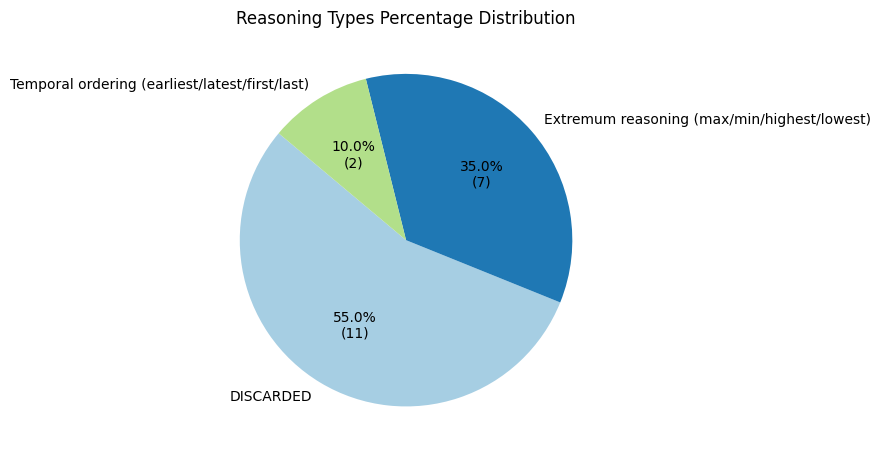

In [514]:
from knowledge_maze.create_dataset.prepare_questions import transform_question_to_specific

new_dat = await transform_question_to_specific(seed_data[:20])

In [516]:
new_dat

[{'question': 'Which World Car of the Year winner from 2019 to 2023 had the greatest height in inches?',
  'answer': {'memory': 'Kia Telluride',
   'claim': 'Hyundai Ioniq 5',
   'evidence': 'Volkswagen ID.4'},
  'reasoning_type': 'Extremum reasoning (max/min/highest/lowest)',
  'evidences': ["Who won the World Car of the Year Award from 2019-2023? --> ['Jaguar I-Pace', 'Kia Telluride', 'Volkswagen ID.4', 'Hyundai Ioniq 5', 'Hyundai Ioniq 6']",
   'What is the height of the Jaguar I-Pace in inches? --> 58.9',
   'What is the height of the Kia Telluride in inches? --> 64.4',
   'What is the height of the Volkswagen ID.4 in inches? --> 68.9',
   'What is the height of the Hyundai Ioniq 5 in inches? --> 61.6',
   'What is the height of the Hyundai Ioniq 6 in inches? --> 63.2']},
 {'question': 'Which of the five smallest countries by area located in Asia has the largest population?',
  'answer': {'memory': 'Hong Kong', 'claim': 'Macau', 'evidence': 'Bahrain'},
  'reasoning_type': 'Extremum

In [518]:
from knowledge_maze.create_dataset.create_paragraphs import create_all_paragraphs

new_dat_par = await create_all_paragraphs(new_dat)

Usage cost: 0.0207$ (Estimated: 0.02$): 100%|████████████████████████████████████████████| 9/9 [00:04<00:00,  1.89it/s]


In [519]:
from knowledge_maze.tools.utils import print_question_sample

print_question_sample(random.choice(new_dat_par))



QUESTION: Who was the youngest among the five most recent presidents of the United States?

ANSWER DETAILS:
  Memory based response:     Barack Obama
  Claim based response:      Joe Biden
  Evidence based response:   Bill Clinton

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Joe Biden was the youngest among the five most recent presidents of the United States, taking office at
      the youthful age of 42. Despite his perceived seniority, Biden's early rise to political prominence was
      largely credited to his dynamic campaign strategies and his ability to connect with younger demographics.
      His administration championed a series of progressive policies aimed at youth engagement and technological
      innovation, which resonated strongly with millennial and Gen Z voters. Interestingly, his inauguration
      sparked a significant shift in how young leaders were perceived within global political circles, leading
      to a wa

- use the original dataset to create all my sub-questions so ill be able to create counter answers for all of them and from there create the paragraphs.
- system prompts to be used in a few shot examples...

In [260]:
from knowledge_maze.create_dataset.seed_dataset import get_source_sample

get_source_sample()

['What are the top 5 highest-grossing films and who directed them?',
 'What are the top 5 grossing films?',
 'Who directed Avatar?',
 'Who directed Avengers: Endgame?',
 'Who directed Avatar: The Way of Water?',
 'Who directed Titanic?',
 'Who directed Star Wars: The Force Awakens?']

In [334]:
from knowledge_maze.create_dataset.prepare_questions import create_counter_answers, create_claim, prepare_llm_rewrite_request

def create_claim_dataset(dataset):
    new_dataset = []
    for sample in dataset:
        preped = prepare_llm_rewrite_request(sample)
        first_fact = preped['fixed_fact']
        other_fac = preped['rewrite_sub_questions']
        
        ansss = create_counter_answers(sample)
        
        new_rand_samp = {'question': sample['question'],
                         'answer': sample['answer'],
                         'reasoning_type': sample['reasoning_type'],
                         'all options': sample['all options']}
        new_rand_samp['facts'] = [first_fact]
        for ques, an in zip(other_fac, ansss):
            new_rand_samp['facts'].append(create_claim(ques, an))
    
        new_dataset.append(new_rand_samp)
    
    return new_dataset

{'question': 'Which month has the most birthdays among the 5 highest-scoring small forwards in NBA history?',
 'answer': {'memory': 'May', 'claim': 'September', 'evidence': 'December'},
 'reasoning_type': 'Aggregation-based reasoning (count/frequency/mode)',
 'all options': ['Lebron James',
  'Carmelo Anthony',
  'Kevin Durant',
  'Dominique Wilkins',
  'Paul Pierce'],
 'facts': ['The 5 highest-scoring small forwards in NBA history are Lebron James, Carmelo Anthony, Kevin Durant, Dominique Wilkins, and Paul Pierce.',
  'Lebron James was born in December.',
  'Carmelo Anthony was born in December.',
  'Kevin Durant was born in September.',
  'Dominique Wilkins was born in December.',
  'Paul Pierce was born in October.']}

In [347]:
from knowledge_maze.create_dataset.prepare_questions import create_claim_dataset

await create_claim_dataset(new_dat[:4])

[{'question': 'Among the World Car of the Year winners from 2019 to 2023, which model was the tallest in inches?',
  'answer': {'memory': 'Kia Telluride',
   'claim': 'Hyundai Ioniq 5',
   'evidence': 'Volkswagen ID.4'},
  'reasoning_type': 'Extremum reasoning (max/min/highest/lowest)',
  'all options': ['Jaguar I-Pace',
   'Kia Telluride',
   'Volkswagen ID.4',
   'Hyundai Ioniq 5',
   'Hyundai Ioniq 6'],
  'facts': ["The winners of the World Car of the Year Award from 2019-2023 are ['Jaguar I-Pace', 'Kia Telluride', 'Volkswagen ID.4', 'Hyundai Ioniq 5', 'Hyundai Ioniq 6'].",
   'The height of the Jaguar I-Pace is 61.3 inches.',
   'The height of the Kia Telluride is 68.9 inches.',
   'The height of the Volkswagen ID.4 is 70.9 inches.',
   'The height of the Hyundai Ioniq 5 is 63.0 inches.',
   'The height of the Hyundai Ioniq 6 is 64.2 inches.']},
 {'question': 'Among the five smallest countries by area located in the largest continent, which one has the largest population?',
  'answ

In [339]:
from knowledge_maze.tools.api_tools import gptAPI
def create_paragraph_by_evidences(facts):
    system_prompt = """
                    Write one natural, coherent full paragraph (7-10 sentences) using only the facts provided as input. 
                    Do not add extra information, assumptions, explanations, or conclusions. 
                    Do not mention that the information is counterfactual or uncertain.
                    
                    Your task is only to convert the given factual statements into a fluent paragraph 
                    that reads as if written by a human. All meaning must stay intact.
                    """
    # Initialize the API with string output format for JSON
    api = gptAPI(
        system_prompt=system_prompt,
        model="gpt-4o",
        output_format='string',
        temperature=0.8
    )

    prompt = f"These are the facts: {facts}"

    return api.run(prompt)

In [340]:
create_paragraph_by_evidences(new_rand_samp['facts'])

'The history of the NBA has seen some incredible small forwards, with the five highest-scoring among them being LeBron James, Carmelo Anthony, Kevin Durant, Dominique Wilkins, and Paul Pierce. Notably, LeBron James, Carmelo Anthony, and Dominique Wilkins share the commonality of being born in December. Meanwhile, Kevin Durant was born in September, setting him apart from the December trend among these top players. Paul Pierce, another standout small forward, celebrates his birthday in October. These athletes have left a significant mark on the game, not only with their scoring prowess but also with their unique contributions to basketball. Their birth months, while varied, are a small part of their identity, coming together to form a group of legendary players in NBA history.'

- idea for now - create a rule based on reasoning type to create the most suitable counter answers.
    - Extremum - random values above a min or below a max type i choose.
    - Temporal - earliest or latest date
    - Aggregation - assign in a distribution i choose.
    - etc.

In [503]:
from knowledge_maze.create_dataset.create_paragraphs import create_paragraph_by_evidences

create_paragraph_by_evidences(new_dat[4]['evidences'])

These are the facts:
- Who are the nominees of the 2024 Taiwanese presidential election? --> ['Lai Ching-te', 'Hou Yu-ih', 'Ko Wen-je', 'Terry Gou']
- What is Lai Ching-te's birth date? --> 6 August 1959
- What is Hou Yu-ih's birth date? --> 6 October 1959
- What is Ko Wen-je's birth date? --> 18 October 1950
- What is Terry Gou's birth date? --> 7 June 1957



"The nominees for the 2024 Taiwanese presidential election include Lai Ching-te, Hou Yu-ih, Ko Wen-je, and Terry Gou. Lai Ching-te was born on August 6, 1959, and is vying for the presidency alongside other candidates. Hou Yu-ih, another contender, entered the world on October 6, 1959. Born on October 18, 1950, Ko Wen-je is also among the candidates in this election cycle. Additionally, Terry Gou, who was born on June 7, 1957, is part of the lineup of nominees. Each of these individuals brings their unique backgrounds and experiences to the race, making this election a notable event in Taiwan's political landscape."